# QUESTION 4 & 5:
4.	**What changed during these 18 months, and what did each change cause?**
5.	**Which North Star Metric would you give this company, and why?**

In [5]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

## 1. Data loading

In [6]:
booking_requests_df = pd.read_csv("cleaned_data/booking_requests.csv")
cleaners_df = pd.read_csv("cleaned_data/cleaners.csv")
customers_df = pd.read_csv("cleaned_data/customers.csv")
marketing_spend_df = pd.read_csv("cleaned_data/marketing_spend.csv")

booking_requests_df.head()

,request_id,customer_id,city,request_date,hours,price_eur,status,cleaner_id,rating,fulfilled,canc,month
0,R0000609,C000609,Lyon,2025-01-14,4,108.0,fulfilled,P00037,5.0,True,False,2025-01-01
1,R0010556,C002995,Bordeaux,2025-05-07,3,81.0,fulfilled,P00186,4.0,True,False,2025-05-01
2,R0001916,C001191,Lyon,2025-02-20,3,81.0,unfulfilled,NaN,NaN,False,False,2025-02-01
3,R0061885,C009288,Paris,2026-01-14,3,81.0,fulfilled,P00212,3.0,True,False,2026-01-01
4,R0015685,C000933,Paris,2025-07-12,3,81.0,fulfilled,P00136,4.0,True,False,2025-07-01


## 2. Question 4


--- Dépenses Marketing (Acquisition Clients vs Cleaners) ---


side,demand,supply
month,,
2025-01-01,10440.0,2790.0
2025-01-02,9530.0,2710.0
2025-01-03,10940.0,2970.0
2025-01-04,13020.0,4570.0
2025-01-05,13910.0,4960.0
2025-01-06,13950.0,6030.0
2025-01-07,16110.0,5230.0
2025-01-08,16120.0,4790.0
2025-01-09,19660.0,6190.0



--- Taux de requêtes non satisfaites (Unfulfilled %) par ville ---


status     unfulfilled_rate_pct                  
city                   Bordeaux Lille  Lyon Paris
month                                            
2025-01-01                  NaN   NaN  57.1   5.7
2025-02-01                  NaN   NaN  21.8   5.6
2025-03-01                  NaN   NaN  47.2   8.8
2025-04-01                  1.4   NaN  35.4   8.9
2025-05-01                  3.4   NaN  29.9   3.5
2025-06-01                  4.4   NaN  26.5   3.3
2025-07-01                  2.9   NaN  22.9   3.8
2025-08-01                  4.3   NaN  28.0   6.5
2025-09-01                  5.7   7.6  33.0   5.9
2025-10-01                  5.8   1.6  32.7   7.1
2025-11-01                  0.7   3.0  30.8   5.0
2025-12-01                  6.1   9.4  29.5   6.2
2026-01-01                  3.1   6.5  34.4   1.9
2026-02-01                  5.5   1.8  33.1   5.0
2026-03-01                  3.0   7.4  33.4   3.7
2026-04-01                  5.8   4.3  39.6   2.1
2026-05-01                  5.5   0.7  36.4   3.7
2026-06-01                  4.9   6.9  41.1   6.5

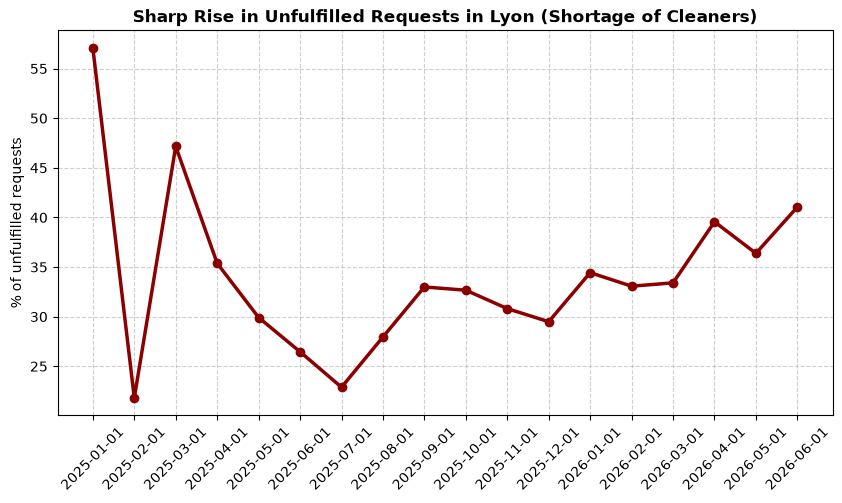

In [14]:
# 1. Marketing spend evolution (Clients Acquisitions vs Cleaners)
spend_trends = marketing_spend_df.groupby(['month', 'side'])['spend_eur'].sum().unstack(fill_value=0)
print("--- Dépenses Marketing (Acquisition Clients vs Cleaners) ---")
display(spend_trends)

# 2. Unfulfilled requests rate evolution
status_counts = booking_requests_df.groupby(['month', 'city', 'status']).size().unstack(fill_value=0)
status_counts['total_requests'] = status_counts.sum(axis=1)
status_counts['unfulfilled_rate_pct'] = (status_counts['unfulfilled'] / status_counts['total_requests']) * 100

print("\n--- Taux de requêtes non satisfaites (Unfulfilled %) par ville ---")
display(status_counts[['unfulfilled_rate_pct']].unstack('city').round(1))

# 3. Visualisation of the supply crisis in Lyon
lyon_data = status_counts.xs('Lyon', level='city')

plt.figure(figsize=(10, 5))
plt.plot(lyon_data.index, lyon_data['unfulfilled_rate_pct'], marker='o', color='darkred', linewidth=2.5) 
plt.title("Sharp Rise in Unfulfilled Requests in Lyon (Shortage of Cleaners)", fontsize=12, fontweight='bold')
plt.ylabel("% of unfulfilled requests")
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 4. Évolution sur 18 mois et impact de l'allocation budgétaire

L'analyse des 18 premiers mois d'exploitation met en évidence un déséquilibre critique entre l'offre et la demande, directement causé par une stratégie d'acquisition asymétrique. L'entreprise a massivement augmenté ses dépenses marketing pour acquérir des clients (passant d'environ 10 400 € à 29 560 €), tout en sous-investissant dans le recrutement des prestataires (stagnant sous les 8 000 €).

Cette dynamique a généré deux situations opposées selon les villes :

- *Crise de l'offre à Lyon* : La croissance de la demande s'est heurtée à une pénurie de cleaners. En conséquence, le taux d'échec (requêtes unfulfilled) a explosé pour atteindre 41,2 % en juin 2026, causant une perte massive de revenus potentiels et une détérioration de l'expérience client.

- *Surcapacité à Paris, Bordeaux et Lille* : L'acquisition de cleaners a très bien fonctionné sur ces marchés, garantissant un taux d'échec historiquement bas (généralement entre 2 % et 7 %). Cependant, l'offre excède largement la demande, ce qui limite le volume d'heures par prestataire (bien en deçà de leur capacité de 30 missions par mois) et augmente le risque de désabonnement (churn) par manque de revenus.

## 3. Question 5

--- North Star Metric and revenus evolution ---


C:\Users\Bérénice\AppData\Local\Temp\ipykernel_62860\3331452382.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  nsm_trends.rename(columns={'hours': 'fulfilled_cleaning_hours'}, inplace=True)


,month,fulfilled_cleaning_hours,gross_booking_value_eur,kozy_net_revenue_eur
0,2025-01-01,1325,35775,7155.0
1,2025-02-01,3250,87750,17550.0
2,2025-03-01,4444,119988,23997.6
3,2025-04-01,6029,162783,32556.6
4,2025-05-01,8190,221130,44226.0
5,2025-06-01,10271,277317,55463.4
6,2025-07-01,12099,326673,65334.6
7,2025-08-01,13311,359397,71879.4
8,2025-09-01,15434,416718,83343.6
9,2025-10-01,17130,462510,92502.0


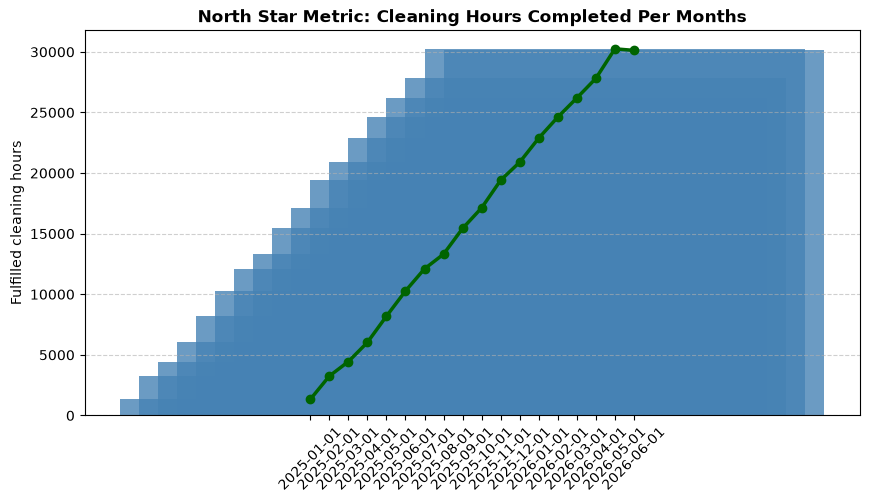

In [29]:
# 1. Filtering only the requests that were fulfilled using the Boolean column
fulfilled_br = booking_requests_df[booking_requests_df['fulfilled'] == True].copy()

# 2. North Star Metric (NSM) per month calculation
nsm_trends = fulfilled_br.groupby('month')['hours'].sum().reset_index()
nsm_trends.rename(columns={'hours': 'fulfilled_cleaning_hours'}, inplace=True)

# 3. Linking NSM to economic value: €27/hour billed, 20% margin for Kozy
nsm_trends['gross_booking_value_eur'] = nsm_trends['fulfilled_cleaning_hours'] * 27
nsm_trends['kozy_net_revenue_eur'] = nsm_trends['gross_booking_value_eur'] * 0.20

print("--- North Star Metric and revenus evolution ---")
display(nsm_trends)

# 4. Plotting
plt.figure(figsize=(10, 5))
plt.bar(nsm_trends['month'], nsm_trends['fulfilled_cleaning_hours'], color='steelblue', width=20, alpha=0.8)
plt.plot(nsm_trends['month'], nsm_trends['fulfilled_cleaning_hours'], color='darkgreen', marker='o', linewidth=2.5)
plt.title("North Star Metric: Cleaning Hours Completed Per Months", fontsize=12, fontweight='bold')
plt.ylabel("Fulfilled cleaning hours")
plt.xticks(rotation=45)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

### 5. Définition de la North Star Metric (NSM)

La North Star Metric stratégique retenue pour Kozy est le nombre d'heures de ménage honorées (**"Fulfilled Cleaning Hours"**).

Pour une marketplace à deux faces, l'indicateur principal doit refléter la liquidité du marché plutôt que la simple acquisition de trafic. Cette métrique est optimale car elle matérialise la création de valeur simultanée pour les trois parties prenantes :

1. Côté Client (Demande) : La garantie d'obtenir un domicile propre (exclut les requêtes unfulfilled ou annulées).

2. Côté Cleaner (Offre) : L'assurance d'obtenir un revenu régulier pour fidéliser la flotte.

3. Côté Plateforme (Business) : Le déclencheur direct de la monétisation, puisque Kozy prélève un take rate de 20 % sur les 27 € payés par heure de prestation honorée.

Piloter l'entreprise par cette NSM forcera les équipes à rééquilibrer activement le budget marketing entre l'acquisition de clients et de cleaners en fonction des besoins spécifiques de chaque ville.